# Entropy, Cross-Entropy, and KL Divergence: the Currency of Uncertainty

**What you'll learn**

- Entropy as *expected surprise* — and its operational meaning: the unbeatable compression
  rate, demonstrated with a Huffman coder built from scratch.
- Cross-entropy as the cost of *using the wrong codebook*, and the exact accounting identity
  H(p, q) = H(p) + KL(p‖q) verified in code.
- Why maximum likelihood **is** KL minimization, and why log loss **is** cross-entropy.
- Forward vs reverse KL — mass-covering vs mode-seeking — the single most useful modern-ML
  intuition about divergences (variational inference, RLHF penalties, distillation).
- The reveal: PSI, Information Value, the G-test, and AIC — tools used elsewhere in this lab
  as "industry formulas" — are all KL divergence in costume.
- Maximum entropy: why the uniform, exponential, and Gaussian are the "assume the least"
  distributions, found numerically.

**Why it matters in interviews**

- "Why is log loss the right loss for classification?" and "explain KL divergence" are
  standard senior applied-scientist probes — and shallow answers are easy to detect.
- Recognizing that PSI and IV are KL is the kind of unification that reads as principal-level
  fluency (and explains the arbitrary-looking thresholds).
- Forward-vs-reverse KL is the vocabulary of the LLM era: fine-tuning drift, distillation,
  variational methods.

Companions: [../04_ml_tabular/06_mutual_information_modern_ml.ipynb](../04_ml_tabular/06_mutual_information_modern_ml.ipynb)
(mutual information, trees, perplexity, temperature, RLHF frontier),
[../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb)
(proper scoring rules), [../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb) (PSI in production),
[../09_finance_and_operations/01_credit_scorecard.ipynb](../09_finance_and_operations/01_credit_scorecard.ipynb) (WOE/IV).

In [1]:
import heapq
import zlib

import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, stats

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

def H_bits(p):
    """Shannon entropy in bits of a discrete distribution (zeros allowed)."""
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

## 1. Entropy is expected surprise

If an event has probability p, its **surprisal** is −log₂ p bits. Rare events are more
surprising; the log makes surprisal *additive* for independent events (the surprise of two
independent things happening is the sum of their surprises — the only continuous choice with
that property). **Entropy is the expected surprisal**:

$$H(X) = -\sum_x p(x)\log_2 p(x) \quad \text{bits}$$

Intuition anchors:
- A fair coin: 1 bit. A fair 8-sided die: 3 bits. A certain event: 0 bits.
- Entropy is maximized by the uniform distribution (nothing is less predictable) and is 0
  exactly when the outcome is certain.

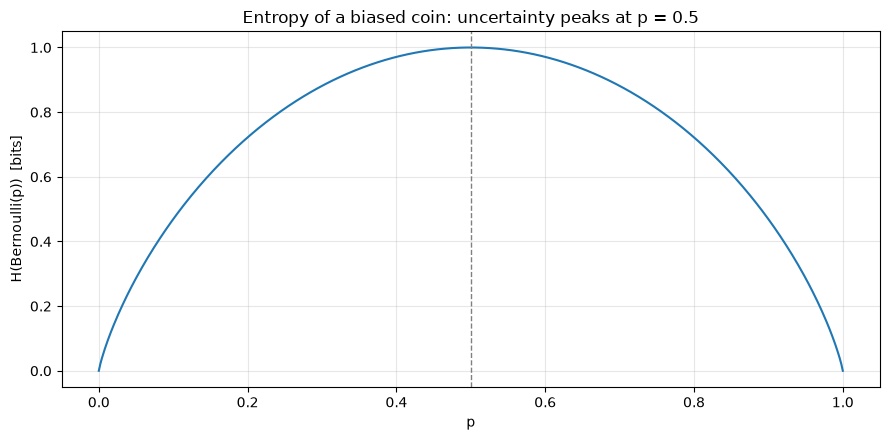

In [2]:
p_grid = np.linspace(1e-6, 1 - 1e-6, 500)
h_bern = -(p_grid * np.log2(p_grid) + (1 - p_grid) * np.log2(1 - p_grid))
fig, ax = plt.subplots()
ax.plot(p_grid, h_bern)
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_xlabel("p")
ax.set_ylabel("H(Bernoulli(p))  [bits]")
ax.set_title("Entropy of a biased coin: uncertainty peaks at p = 0.5")
plt.tight_layout(); plt.show()

Note the shape: entropy is *flat near p = 0.5* and falls off a cliff near the edges. A 60/40
process is barely more predictable than a coin flip; a 99/1 process is almost deterministic.

### A business use you already need: concentration of a mix

"How diversified is our traffic?" is an entropy question. Top-1 share throws away the rest of
the distribution; entropy uses all of it. Even better, **exp(H in nats)** — the *effective
number of categories* (called perplexity in language modeling) — answers in interpretable
units: "we effectively have 3.2 channels."

In [3]:
channels = ["organic", "paid_search", "social", "email", "affiliate", "direct"]
mix_a = np.array([0.72, 0.10, 0.07, 0.05, 0.04, 0.02])   # dominated by organic
mix_b = np.array([0.25, 0.22, 0.18, 0.15, 0.12, 0.08])   # balanced

def H_nats(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-(p * np.log(p)).sum())

for name, mix in [("A (concentrated)", mix_a), ("B (balanced)", mix_b)]:
    print(f"Mix {name}: top-1 share {mix.max():.0%} | entropy {H_bits(mix):.2f} bits "
          f"| effective # channels {np.exp(H_nats(mix)):.1f}  (max possible {len(mix)})")

Mix A (concentrated): top-1 share 72% | entropy 1.46 bits | effective # channels 2.7  (max possible 6)
Mix B (balanced): top-1 share 25% | entropy 2.50 bits | effective # channels 5.6  (max possible 6)


Same six channels, very different exposure: mix A behaves like ~2.6 channels, mix B like ~5.7.
The same arithmetic powers portfolio-concentration checks, recommendation-diversity metrics,
and "is one segment quietly dominating this metric?" investigations.

### Conditional entropy and the chain rule

H(Y|X) is the surprise *remaining* in Y once you know X. Information can only help:
H(Y|X) ≤ H(Y), and the drop is the **mutual information** I(X;Y) — the star of the
[companion notebook](../04_ml_tabular/06_mutual_information_modern_ml.ipynb). Let's verify the
accounting on a small business joint distribution.

In [4]:
# Joint distribution of device and conversion, p(device, converted)
devices = ["mobile", "desktop", "tablet"]
joint = np.array([
    #  no-conv   conv
    [0.55,      0.017],   # mobile: heavy traffic, ~3.0% conversion
    [0.33,      0.028],   # desktop: less traffic, ~7.8% conversion
    [0.068,     0.002],   # tablet
])
joint = joint / joint.sum()
p_dev = joint.sum(axis=1)
p_conv = joint.sum(axis=0)

H_conv = H_bits(p_conv)
H_conv_given_dev = sum(p_dev[i] * H_bits(joint[i] / p_dev[i]) for i in range(3))
H_joint = H_bits(joint.ravel())
H_dev = H_bits(p_dev)

print(f"H(conversion)               = {H_conv:.4f} bits")
print(f"H(conversion | device)      = {H_conv_given_dev:.4f} bits  (knowing device helps a little)")
print(f"I(device; conversion)       = {H_conv - H_conv_given_dev:.4f} bits")
print(f"Chain rule check: H(dev, conv) = {H_joint:.4f}  vs  H(dev) + H(conv|dev) = "
      f"{H_dev + sum(p_dev[i] * H_bits(joint[i]/p_dev[i]) for i in range(3)):.4f}")

H(conversion)               = 0.2745 bits
H(conversion | device)      = 0.2663 bits  (knowing device helps a little)
I(device; conversion)       = 0.0082 bits
Chain rule check: H(dev, conv) = 1.5287  vs  H(dev) + H(conv|dev) = 1.5287


Device carries a sliver of information about conversion (a few thousandths of a bit — real but
small, which matches the ~3% vs ~8% conversion rates involved). This "small numbers of bits for
realistic effects" calibration is worth internalizing: **most business signals are milli-bit to
centi-bit signals.**

## 2. The operational meaning: entropy is the compression limit

Shannon's source-coding theorem makes entropy *physical*: no lossless code can average fewer
than H bits per symbol, and good codes get within 1 bit of it. Let's earn that claim: build a
Huffman coder from scratch and race it against the entropy bound.

In [5]:
def huffman_lengths(probs):
    """Return optimal prefix-free code lengths (bits/symbol) for each symbol."""
    heap = [(p, i, (i,)) for i, p in enumerate(probs)]   # (prob, tiebreak, symbols)
    heapq.heapify(heap)
    lengths = np.zeros(len(probs))
    counter = len(probs)
    while len(heap) > 1:
        p1, _, s1 = heapq.heappop(heap)
        p2, _, s2 = heapq.heappop(heap)
        for s in s1 + s2:
            lengths[s] += 1                              # one level deeper in the tree
        heapq.heappush(heap, (p1 + p2, counter, s1 + s2))
        counter += 1
    return lengths

p_source = np.array([0.45, 0.25, 0.12, 0.08, 0.05, 0.03, 0.015, 0.005])
L = huffman_lengths(p_source)
avg_len = (p_source * L).sum()
print("symbol probs :", p_source)
print("code lengths :", L.astype(int))
print(f"Entropy H(p)        = {H_bits(p_source):.3f} bits/symbol")
print(f"Huffman average     = {avg_len:.3f} bits/symbol   (≥ H, within 1 bit — Shannon honored)")
print(f"Naive fixed-length  = {np.log2(len(p_source)):.0f} bits/symbol")

symbol probs : [0.45  0.25  0.12  0.08  0.05  0.03  0.015 0.005]
code lengths : [1 2 3 4 5 6 7 7]
Entropy H(p)        = 2.174 bits/symbol
Huffman average     = 2.200 bits/symbol   (≥ H, within 1 bit — Shannon honored)
Naive fixed-length  = 3 bits/symbol


The skewed source needs ~2.2 bits/symbol, not 3: predictability *is* compressibility. A fun
corollary you can try on any dataset: a general-purpose compressor is an entropy meter.

In [6]:
n_chars = 200_000
skewed = rng.choice(list("abcdefgh"), p=p_source, size=n_chars)
uniform = rng.choice(list("abcdefgh"), size=n_chars)
for name, arr, true_h in [("skewed (H≈2.17)", skewed, H_bits(p_source)),
                          ("uniform (H=3.00)", uniform, 3.0)]:
    comp = zlib.compress("".join(arr).encode(), level=9)
    print(f"{name:18s}: zlib → {8 * len(comp) / n_chars:.2f} bits/char  (entropy {true_h:.2f})")

skewed (H≈2.17)   : zlib → 2.65 bits/char  (entropy 2.17)
uniform (H=3.00)  : zlib → 3.45 bits/char  (entropy 3.00)


zlib tracks the entropy of each source (a bit above it — real coders pay format overhead,
and zlib is not an optimal symbol coder).
**Prediction and compression are the same problem** — remember this when we reach language
models and perplexity in the companion notebook.

## 3. Cross-entropy: the cost of the wrong codebook

Suppose the data come from p but you built your code (or your model) for q. You now pay

$$H(p, q) = -\sum_x p(x)\log_2 q(x) = H(p) + \mathrm{KL}(p\|q)$$

bits per symbol. The identity is the whole story:

- **H(p)** — the unavoidable cost (the world's intrinsic uncertainty),
- **KL(p‖q)** — the *excess* cost caused by your model being wrong. Always ≥ 0 (Gibbs'
  inequality), and 0 only when q = p.

So KL divergence is not an abstract "distance": it is **wasted bits per observation**. Let's
verify with real codes.

In [7]:
q_source = np.array([0.10, 0.10, 0.15, 0.15, 0.15, 0.15, 0.10, 0.10])  # wrong beliefs
Lq = huffman_lengths(q_source)

avg_len_wrong = (p_source * Lq).sum()             # p's data, q's codebook
cross_entropy = -(p_source * np.log2(q_source)).sum()
kl_pq = (p_source * np.log2(p_source / q_source)).sum()

print(f"Huffman codebook built for q, applied to p's data: {avg_len_wrong:.3f} bits/symbol")
print(f"Exact ideal lengths (-log2 q) under p:             {cross_entropy:.3f} bits/symbol")
print("  (the integer-length Huffman code tracks the ideal within a bit; the identity is exact:)")
print(f"Cross-entropy H(p,q) = {cross_entropy:.3f} bits  =  H(p) {H_bits(p_source):.3f} + KL(p||q) {kl_pq:.3f}")
print(f"→ believing q while the world is p wastes {kl_pq:.3f} bits on every single symbol")

Huffman codebook built for q, applied to p's data: 3.000 bits/symbol
Exact ideal lengths (-log2 q) under p:             3.158 bits/symbol
  (the integer-length Huffman code tracks the ideal within a bit; the identity is exact:)
Cross-entropy H(p,q) = 3.158 bits  =  H(p) 2.174 + KL(p||q) 0.984
→ believing q while the world is p wastes 0.984 bits on every single symbol


In [8]:
kl_qp = (q_source * np.log2(q_source / p_source)).sum()
print(f"KL(p||q) = {kl_pq:.3f} bits   vs   KL(q||p) = {kl_qp:.3f} bits   → NOT symmetric")
print("KL is not a metric: it is asymmetric and violates the triangle inequality.")
print("The two directions answer different questions — section 5 shows why that matters.")

KL(p||q) = 0.984 bits   vs   KL(q||p) = 1.127 bits   → NOT symmetric
KL is not a metric: it is asymmetric and violates the triangle inequality.
The two directions answer different questions — section 5 shows why that matters.


## 4. Maximum likelihood IS KL minimization, and log loss IS cross-entropy

Given data from p, choosing model q to maximize likelihood is *exactly* choosing q to minimize
the empirical cross-entropy −(1/n)Σ log q(xᵢ), which estimates H(p) + KL(p‖q). Since H(p) is
fixed by the world, **MLE = minimize KL(p‖q)**: find the model that wastes the fewest bits.

In [9]:
data = rng.normal(3.0, 1.5, size=2000)

def empirical_cross_entropy_nats(theta):
    mu, log_sd = theta
    return -stats.norm.logpdf(data, mu, np.exp(log_sd)).mean()

opt = optimize.minimize(empirical_cross_entropy_nats, x0=[0.0, 0.0], method="Nelder-Mead")
mu_hat, sd_hat = opt.x[0], np.exp(opt.x[1])
print(f"argmin cross-entropy: mu = {mu_hat:.4f}, sd = {sd_hat:.4f}")
print(f"sample moments      : mu = {data.mean():.4f}, sd = {data.std():.4f}  ← identical: MLE")

argmin cross-entropy: mu = 3.0201, sd = 1.5247
sample moments      : mu = 3.0202, sd = 1.5247  ← identical: MLE


In [10]:
# And classification log loss is cross-entropy, computed per example against a one-hot p:
from sklearn.metrics import log_loss

y_true = np.array([1, 0, 1, 1, 0])
p_pred = np.array([0.9, 0.2, 0.6, 0.99, 0.4])
manual_nats = -np.mean(y_true * np.log(p_pred) + (1 - y_true) * np.log(1 - p_pred))
print(f"sklearn log_loss: {log_loss(y_true, p_pred):.6f} nats")
print(f"manual cross-entropy: {manual_nats:.6f} nats  ( = {manual_nats/np.log(2):.4f} bits/example)")

sklearn log_loss: 0.272041 nats
manual cross-entropy: 0.272041 nats  ( = 0.3925 bits/example)


Two consequences worth saying out loud in an interview:

1. **Training a classifier on log loss = compressing the labels given the features.** A model
   with test log loss of 0.15 nats/example literally defines a code that stores each label in
   0.22 bits given the features.
2. Log loss is a **strictly proper scoring rule** (honesty-optimal — see
   [../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb)),
   and among proper rules it is the *local* one: it scores only the probability you assigned to
   what happened. That's why it, and not squared error on probabilities, is the canonical
   training objective.

## 5. Forward vs reverse KL: mass-covering vs mode-seeking

Because KL is asymmetric, "make q close to p" is two different problems:

- **Forward KL(p‖q)** = E_p[log p/q]: p is the referee. q gets *infinitely* punished for
  assigning ~zero probability where p has mass → q must **cover** everything p does
  (mass-covering / mean-seeking). This is the MLE direction.
- **Reverse KL(q‖p)** = E_q[log q/p]: q is the referee. q is punished for putting its own mass
  where p has none, but pays nothing for *ignoring* parts of p → q **retreats into one mode**
  (mode-seeking, zero-forcing). This is the variational-inference direction.

Fit a single Gaussian to a bimodal truth both ways and watch the philosophies diverge:

In [11]:
xs = np.linspace(-8, 8, 4001)
dx = xs[1] - xs[0]
p_mix = 0.5 * stats.norm.pdf(xs, -2, 0.6) + 0.5 * stats.norm.pdf(xs, 2, 0.6)
p_mix /= p_mix.sum() * dx

def q_of(theta):
    q = stats.norm.pdf(xs, theta[0], np.exp(theta[1]))
    return np.maximum(q / (q.sum() * dx), 1e-300)

def kl_forward(theta):                       # KL(p || q)
    q = q_of(theta)
    return float(np.sum(p_mix * np.log(np.maximum(p_mix, 1e-300) / q)) * dx)

def kl_reverse(theta):                       # KL(q || p)
    q = q_of(theta)
    return float(np.sum(q * np.log(q / np.maximum(p_mix, 1e-300))) * dx)

fw = optimize.minimize(kl_forward, [0.5, 0.0], method="Nelder-Mead")
rv_left = optimize.minimize(kl_reverse, [-1.5, -0.5], method="Nelder-Mead")
rv_right = optimize.minimize(kl_reverse, [1.5, -0.5], method="Nelder-Mead")

print(f"forward KL(p||q) minimizer : mu = {fw.x[0]:>5.2f}, sd = {np.exp(fw.x[1]):.2f}  (covers both modes)")
print(f"reverse KL(q||p), init left : mu = {rv_left.x[0]:>5.2f}, sd = {np.exp(rv_left.x[1]):.2f}")
print(f"reverse KL(q||p), init right: mu = {rv_right.x[0]:>5.2f}, sd = {np.exp(rv_right.x[1]):.2f}")
print("→ reverse KL has one local optimum per mode: it PICKS a mode and commits.")

forward KL(p||q) minimizer : mu = -0.00, sd = 2.09  (covers both modes)
reverse KL(q||p), init left : mu = -2.00, sd = 0.60
reverse KL(q||p), init right: mu =  2.00, sd = 0.60
→ reverse KL has one local optimum per mode: it PICKS a mode and commits.


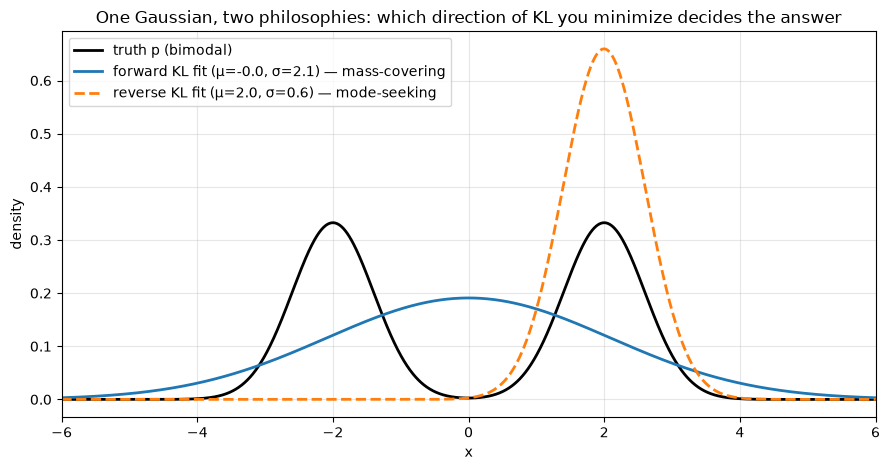

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(xs, p_mix, "k", lw=2, label="truth p (bimodal)")
ax.plot(xs, q_of(fw.x), lw=2, label=f"forward KL fit (μ={fw.x[0]:.1f}, σ={np.exp(fw.x[1]):.1f}) — mass-covering")
ax.plot(xs, q_of(rv_right.x), lw=2, ls="--",
        label=f"reverse KL fit (μ={rv_right.x[0]:.1f}, σ={np.exp(rv_right.x[1]):.1f}) — mode-seeking")
ax.set_xlim(-6, 6); ax.set_xlabel("x"); ax.set_ylabel("density")
ax.set_title("One Gaussian, two philosophies: which direction of KL you minimize decides the answer")
ax.legend(); plt.tight_layout(); plt.show()

Where you meet each direction in the wild:

| Direction | Behavior | Where it appears |
|---|---|---|
| Forward KL(p‖q) | cover all of p; blurry but never misses a region | MLE / cross-entropy training; distillation against teacher probabilities |
| Reverse KL(q‖p) | commit to one mode; sharp but can ignore regions | variational inference; RLHF-style KL-to-base penalties (policy stays where the base model has mass) |

**Jensen–Shannon divergence** = ½KL(p‖m) + ½KL(q‖m) with m = ½(p+q): symmetric, bounded
(≤ 1 bit), defined even with disjoint supports. Historically the original GAN objective;
practically, a safe default when you just need a symmetric "how different are these two
distributions" number.

## 6. KL in costume: four tools you already use

This lab has been using KL divergence all along, under industry aliases. Unmasking them is more
than trivia — it explains their properties and their thresholds.

### 6a. PSI (drift monitoring) = symmetrized KL

The Population Stability Index of
[../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb):
PSI = Σ (aᵢ − eᵢ)·ln(aᵢ/eᵢ) over bins. Algebraically that is exactly KL(a‖e) + KL(e‖a)
(Jeffreys' J-divergence), in nats.

In [13]:
expected = rng.normal(600, 50, 20_000)                 # scores at development time
actual = rng.normal(585, 55, 20_000)                   # drifted production scores
edges = np.quantile(expected, np.linspace(0, 1, 11))
edges[0], edges[-1] = -np.inf, np.inf
e = np.histogram(expected, edges)[0] / len(expected)
a = np.histogram(actual, edges)[0] / len(actual)
e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)

psi_industry = ((a - e) * np.log(a / e)).sum()
kl_ae = (a * np.log(a / e)).sum()
kl_ea = (e * np.log(e / a)).sum()
print(f"PSI (industry formula)      = {psi_industry:.4f}")
print(f"KL(a||e) + KL(e||a)         = {kl_ae + kl_ea:.4f}   ← identical")
print("The 0.1 / 0.25 'rules of thumb' are just conventional cut points on a KL scale —")
print("which is why they are arbitrary, and why PSI explodes on empty bins (KL support mismatch).")

PSI (industry formula)      = 0.0851
KL(a||e) + KL(e||a)         = 0.0851   ← identical
The 0.1 / 0.25 'rules of thumb' are just conventional cut points on a KL scale —
which is why they are arbitrary, and why PSI explodes on empty bins (KL support mismatch).


### 6b. Information Value (credit scoring) = the same J-divergence

IV from [../09_finance_and_operations/01_credit_scorecard.ipynb](../09_finance_and_operations/01_credit_scorecard.ipynb):
IV = Σ (%goodᵢ − %badᵢ)·WOEᵢ with WOEᵢ = ln(%goodᵢ/%badᵢ). Same algebra, different costume:
**IV is the symmetrized KL between the score distribution of goods and of bads** — i.e. a
separability measure. "IV > 0.3 = strong predictor" is "the class-conditional distributions are
≥ 0.3 nats apart."

In [14]:
goods = rng.normal(620, 55, 30_000)                    # feature among non-defaulters
bads = rng.normal(560, 60, 3_000)                      # feature among defaulters
edges_iv = np.quantile(np.r_[goods, bads], np.linspace(0, 1, 11))
edges_iv[0], edges_iv[-1] = -np.inf, np.inf
g = np.clip(np.histogram(goods, edges_iv)[0] / len(goods), 1e-6, None)
b = np.clip(np.histogram(bads, edges_iv)[0] / len(bads), 1e-6, None)
iv = ((g - b) * np.log(g / b)).sum()
print(f"Information Value = {iv:.3f}  =  KL(g||b) + KL(b||g) = "
      f"{(g*np.log(g/b)).sum() + (b*np.log(b/g)).sum():.3f} nats")

Information Value = 1.052  =  KL(g||b) + KL(b||g) = 1.052 nats


### 6c. The G-test: the likelihood-ratio χ² is 2n·KL

For a contingency table, the G statistic 2·ΣO·ln(O/E) equals **2n · KL(observed‖expected)**
(nats). Pearson's χ² is its second-order Taylor approximation — which is why the two tests
agree on large samples and diverge on sparse tables.

In [15]:
table = np.array([[420, 380], [1580, 1620]])           # e.g. conversion by variant
n_tab = table.sum()
row_p, col_p = table.sum(1) / n_tab, table.sum(0) / n_tab
expected_tab = np.outer(row_p, col_p) * n_tab

G_manual = 2 * (table * np.log(table / expected_tab)).sum()
obs_p, exp_p = table / n_tab, expected_tab / n_tab
print(f"G statistic (manual)          = {G_manual:.4f}")
print(f"2n * KL(observed||expected)   = {2 * n_tab * (obs_p * np.log(obs_p/exp_p)).sum():.4f}")
g_scipy, p_g, *_ = stats.chi2_contingency(table, lambda_="log-likelihood", correction=False)[:4]
chi2_scipy, p_chi2, *_ = stats.chi2_contingency(table, correction=False)[:4]
print(f"scipy G-test                  = {g_scipy:.4f} (p={p_g:.4f})")
print(f"scipy Pearson chi2            = {chi2_scipy:.4f} (p={p_chi2:.4f})  ← Taylor approx of G")

G statistic (manual)          = 2.5008
2n * KL(observed||expected)   = 2.5008
scipy G-test                  = 2.5008 (p=0.1138)
scipy Pearson chi2            = 2.5000 (p=0.1138)  ← Taylor approx of G


### 6d. AIC: model selection as expected-KL minimization

Akaike's criterion AIC = 2k − 2·ln L̂ is an (asymptotically unbiased) estimate of the expected
KL divergence from the truth to your fitted model, up to constants. "Pick lowest AIC" *means*
"pick the model expected to waste the fewest bits on the next dataset." The −2·ln L̂ term is the
in-sample cross-entropy; the +2k term corrects the optimism of evaluating a model on the data
that tuned it. Watch AIC track true out-of-sample cross-entropy on a polynomial ladder:

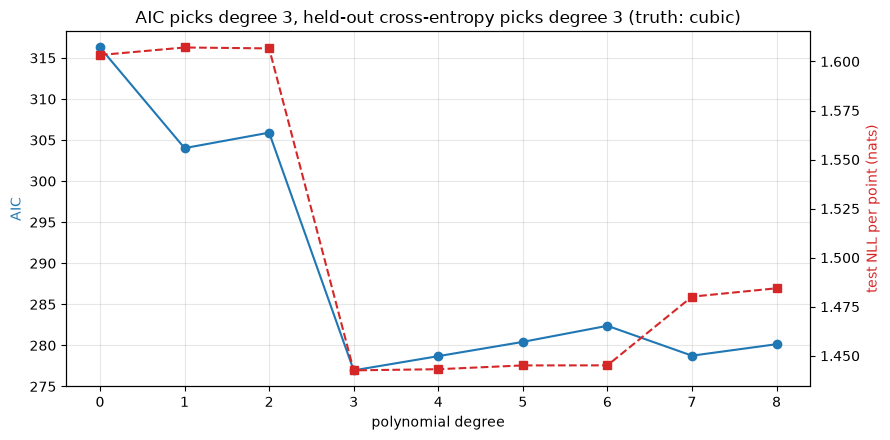

In [16]:
def gaussian_nll(y, yhat):                      # per-point NLL with MLE sigma, in nats
    resid = y - yhat
    sig2 = resid.var()
    return 0.5 * (np.log(2 * np.pi * sig2) + 1)

n_fit = 100
x_fit = rng.uniform(-2, 2, n_fit)
f_true = lambda x: 0.5 * x**3 - x + 1
y_fit = f_true(x_fit) + rng.normal(0, 1.0, n_fit)
x_test = rng.uniform(-2, 2, 20_000)
y_test = f_true(x_test) + rng.normal(0, 1.0, 20_000)

degrees = np.arange(0, 9)
aics, test_ces = [], []
for d in degrees:
    coefs = np.polyfit(x_fit, y_fit, d)
    nll_in = gaussian_nll(y_fit, np.polyval(coefs, x_fit)) * n_fit
    k = d + 2                                   # coefficients + noise variance
    aics.append(2 * k + 2 * nll_in)
    resid_t = y_test - np.polyval(coefs, x_test)
    sig2_in = (y_fit - np.polyval(coefs, x_fit)).var()
    test_ces.append(0.5 * np.log(2 * np.pi * sig2_in) + 0.5 * resid_t.var() / sig2_in
                    + 0.5 * (resid_t.mean()**2) / sig2_in)

fig, ax1 = plt.subplots()
ax1.plot(degrees, aics, "o-", color="tab:blue", label="AIC (in-sample)")
ax1.set_xlabel("polynomial degree"); ax1.set_ylabel("AIC", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(degrees, test_ces, "s--", color="tab:red", label="held-out cross-entropy")
ax2.set_ylabel("test NLL per point (nats)", color="tab:red"); ax2.grid(False)
ax1.set_title(f"AIC picks degree {degrees[np.argmin(aics)]}, held-out cross-entropy picks "
              f"degree {degrees[np.argmin(test_ces)]} (truth: cubic)")
plt.tight_layout(); plt.show()

(Mutual information — KL between the joint and the product of marginals — is the fifth family
member, and gets the [whole companion notebook](../04_ml_tabular/06_mutual_information_modern_ml.ipynb).)

## 7. Maximum entropy: "assume the least"

Among all distributions satisfying what you *know* (support, mean, variance…), the
**maximum-entropy** distribution adds the fewest additional assumptions — every bit of entropy
below the max is a claim you didn't have evidence for. This is why the defaults of statistics
are what they are:

| You know | MaxEnt distribution |
|---|---|
| support {1..k} only | uniform |
| support ℝ⁺, mean | exponential |
| support ℝ, mean and variance | **Gaussian** |

Classic demo (Jaynes' "Brandeis dice"): a die averages 4.5 instead of 3.5. What's the least-
committal pmf consistent with that? Solve numerically and check the known exponential-family form:

numeric MaxEnt pmf : [0.0544 0.0788 0.1142 0.1655 0.2398 0.3475]
exponential tilt   : [0.0544 0.0788 0.1142 0.1654 0.2398 0.3475]   (λ = 0.371)
max |difference|   : 1.68e-05  → MaxEnt = exponential family


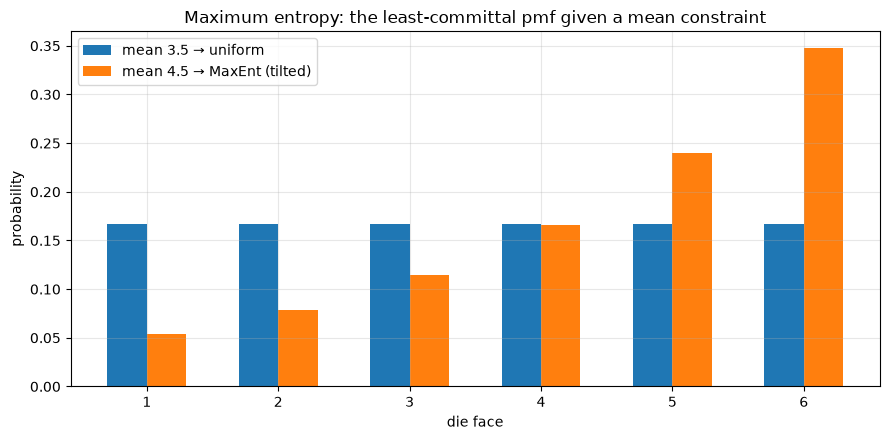

In [17]:
faces = np.arange(1, 7)

res = optimize.minimize(
    lambda p: (p * np.log(np.maximum(p, 1e-12))).sum(),          # minimize -H
    x0=np.ones(6) / 6, method="SLSQP", bounds=[(1e-9, 1)] * 6,
    constraints=[{"type": "eq", "fun": lambda p: p.sum() - 1},
                 {"type": "eq", "fun": lambda p: (p * faces).sum() - 4.5}])
p_maxent = res.x

lam = optimize.brentq(lambda l: (np.exp(l * faces) * faces).sum() / np.exp(l * faces).sum() - 4.5, -2, 2)
p_theory = np.exp(lam * faces) / np.exp(lam * faces).sum()

print("numeric MaxEnt pmf :", np.round(p_maxent, 4))
print("exponential tilt   :", np.round(p_theory, 4), f"  (λ = {lam:.3f})")
print(f"max |difference|   : {np.abs(p_maxent - p_theory).max():.2e}  → MaxEnt = exponential family")

fig, ax = plt.subplots()
ax.bar(faces - 0.15, np.ones(6) / 6, width=0.3, label="mean 3.5 → uniform")
ax.bar(faces + 0.15, p_maxent, width=0.3, label="mean 4.5 → MaxEnt (tilted)")
ax.set_xlabel("die face"); ax.set_ylabel("probability")
ax.set_title("Maximum entropy: the least-committal pmf given a mean constraint")
ax.legend(); plt.tight_layout(); plt.show()

The solution is a *smooth exponential tilt* — not, say, "put all extra mass on 6", which would
satisfy the constraint while smuggling in strong extra structure. Two footnotes worth knowing:
logistic regression is the maximum-entropy classifier given feature expectations, and
exponential tilting is exactly how we'll model "fine-tuning against a reward with a KL leash"
in the companion notebook.

## 8. Pitfalls

### Pitfall 1: plug-in entropy is biased low at small n

In [18]:
K = 20
true_H = np.log2(K)
sizes = [25, 50, 100, 400, 1600]
print(f"true entropy of uniform over {K} categories: {true_H:.3f} bits")
for n_s in sizes:
    ests, corr = [], []
    for _ in range(400):
        counts = np.bincount(rng.integers(0, K, n_s), minlength=K)
        ph = counts / n_s
        h = H_bits(ph)
        ests.append(h)
        k_obs = (counts > 0).sum()
        corr.append(h + (k_obs - 1) / (2 * n_s * np.log(2)))     # Miller–Madow
    print(f"n={n_s:>5}: plug-in {np.mean(ests):.3f} bits (bias {np.mean(ests)-true_H:+.3f}) | "
          f"Miller–Madow {np.mean(corr):.3f}")

true entropy of uniform over 20 categories: 4.322 bits
n=   25: plug-in 3.674 bits (bias -0.648) | Miller–Madow 4.061
n=   50: plug-in 4.013 bits (bias -0.309) | Miller–Madow 4.265
n=  100: plug-in 4.177 bits (bias -0.145) | Miller–Madow 4.314
n=  400: plug-in 4.287 bits (bias -0.035) | Miller–Madow 4.322
n= 1600: plug-in 4.313 bits (bias -0.009) | Miller–Madow 4.322


Unseen categories look impossible to the plug-in estimator, so it *systematically* underestimates
entropy (and overestimates mutual information — the companion notebook demonstrates that side).
Corrections help; more data helps more; comparing entropies across different n or bin counts
without thinking is how people fool themselves.

### Pitfall 2: KL blows up on support mismatch

If q(x) = 0 anywhere p(x) > 0, KL(p‖q) = ∞ — one empty bin ruins the number. That's not a bug:
a model that says "impossible" about something that happens deserves infinite loss. Practically
it's why PSI implementations clip empty bins, why log loss clips probabilities, and why Laplace
smoothing exists in language models.

### Pitfall 3: treating KL as a distance

KL(p‖q) ≠ KL(q‖p), and the direction is a modeling decision, not a detail (section 5). If you
need symmetry, say J-divergence or JS explicitly.

### Pitfall 4: differential entropy is not "entropy but continuous"

In [19]:
for sd in [1.0, 0.05]:
    h = 0.5 * np.log2(2 * np.pi * np.e * sd**2)
    print(f"differential entropy of N(0, {sd}) = {h:+.2f} bits  {'(negative!)' if h < 0 else ''}")
print(f"...and measuring the same quantity in different units shifts it by log2(scale): "
      f"{0.5*np.log2(2*np.pi*np.e*1.0**2) - 0.5*np.log2(2*np.pi*np.e*0.01**2):.2f} bits (m → cm)")

differential entropy of N(0, 1.0) = +2.05 bits  
differential entropy of N(0, 0.05) = -2.27 bits  (negative!)
...and measuring the same quantity in different units shifts it by log2(scale): 6.64 bits (m → cm)


Differential entropy can be negative and changes under unit conversion — only *differences* of
differential entropies (like KL and mutual information, which are unit-invariant) are safe to
interpret across representations.

## 9. Interview corner

**Q1. "Explain entropy to a PM."**
The number of yes/no questions you'd need, on average, to pin down the outcome — equivalently,
how many bits it takes to store it. A traffic mix with entropy of about 1.5 bits behaves like
~2.7 equally likely channels. High entropy = hard to predict = incompressible.

**Q2. "Why is log loss the right loss for probabilistic classifiers?"**
It's cross-entropy: the bits your model wastes vs the truth, decomposing as irreducible
uncertainty plus KL(truth‖model). Minimizing it is MLE, it's strictly proper (honesty-optimal),
and it's local (scores only the probability of what happened). Squared error on probabilities
is proper but not local; accuracy is not proper at all.

**Q3. "KL(p‖q) vs KL(q‖p) — does the direction matter?"**
Completely. Forward KL punishes missing mass (mass-covering — the MLE/distillation direction);
reverse KL punishes inventing mass (mode-seeking — the variational/RLHF direction). Fitting a
unimodal model to a bimodal truth gives a wide blur one way and a committed single mode the other.

**Q4. "What do PSI = 0.25 and IV = 0.3 actually measure?"**
Both are the symmetrized KL divergence (in nats) between two binned distributions — production
vs development scores for PSI, goods vs bads for IV. The thresholds are conventions on a KL
scale, not laws; and both explode on empty bins because KL does.

**Q5. "G-test vs Pearson chi-square?"**
G = 2n·KL(observed‖expected); Pearson's χ² is its quadratic approximation. Same asymptotics,
different small-sample/sparse-table behavior; G adds across nested partitions cleanly.

**Q6. "Why do people call the Gaussian the 'least informative' choice?"**
MaxEnt: among all distributions with the given mean and variance it has maximum entropy — any
other choice encodes extra structure you didn't claim to know. Same logic gives uniform
(support only) and exponential (positive support + mean).

## 10. Key takeaways

- Entropy = expected surprise = the provable compression limit; exp(H) gives the *effective
  number of outcomes* — the same quantity language models call perplexity.
- Cross-entropy = entropy + KL: the wasted-bits decomposition. **KL is excess cost, per
  observation, of believing q when the world is p.**
- MLE = cross-entropy minimization = KL minimization; log loss is cross-entropy, strictly
  proper and local.
- Forward KL covers mass; reverse KL seeks modes. The direction is a modeling decision you
  should be able to defend.
- PSI, IV, the G-test, and AIC are KL in costume — one concept, four dashboards.
- Maximum entropy is the "assume the least" principle that explains the canonical
  distributions (and logistic regression).
- Plug-in information estimates bias low on entropy (and high on MI) at small n; KL is
  infinite under support mismatch; differential entropy is only meaningful in differences.

## 11. Exercises

**Exercise 1 — The accounting identity, empirically.** Generate random distribution pairs
(p, q) over 10 outcomes and verify numerically that E_p[−log₂ q] = H(p) + KL(p‖q) for all of
them, and that KL ≥ 0 with equality iff p = q.

In [20]:
# --- Solution ---
max_gap, min_kl = 0.0, np.inf
for _ in range(1000):
    p_ = rng.dirichlet(np.ones(10))
    q_ = rng.dirichlet(np.ones(10))
    ce = -(p_ * np.log2(q_)).sum()
    hp = H_bits(p_)
    kl = (p_ * np.log2(p_ / q_)).sum()
    max_gap = max(max_gap, abs(ce - (hp + kl)))
    min_kl = min(min_kl, kl)
kl_self = (p_ * np.log2(p_ / p_)).sum()
print(f"max |H(p,q) − (H(p)+KL)| over 1000 pairs: {max_gap:.2e}")
print(f"smallest KL(p||q) seen (random pairs):    {min_kl:.4f}  (> 0)")
print(f"KL(p||p) = {kl_self:.1f}")

max |H(p,q) − (H(p)+KL)| over 1000 pairs: 1.78e-15
smallest KL(p||q) seen (random pairs):    0.1896  (> 0)
KL(p||p) = 0.0


**Exercise 2 — Gaussian is MaxEnt for fixed mean and variance.** Discretize [−6, 6] and
numerically maximize entropy subject to mean 0 and variance 1. Compare the result to the
discretized standard normal, and to two other unit-variance distributions.

In [21]:
# --- Solution ---
xs2 = np.linspace(-6, 6, 121)
res2 = optimize.minimize(
    lambda p: (p * np.log(np.maximum(p, 1e-12))).sum(),
    x0=np.ones(len(xs2)) / len(xs2), method="SLSQP", bounds=[(1e-12, 1)] * len(xs2),
    constraints=[{"type": "eq", "fun": lambda p: p.sum() - 1},
                 {"type": "eq", "fun": lambda p: (p * xs2).sum()},
                 {"type": "eq", "fun": lambda p: (p * xs2**2).sum() - 1}],
    options={"maxiter": 500})
p_me = res2.x
p_gauss = stats.norm.pdf(xs2); p_gauss /= p_gauss.sum()
# a unit-variance two-point distribution and a uniform, for comparison
p_two = np.zeros(len(xs2)); p_two[np.argmin(np.abs(xs2+1))] = p_two[np.argmin(np.abs(xs2-1))] = 0.5
half = np.abs(xs2) <= np.sqrt(3)
p_unif = half / half.sum()
print(f"H(maxent solution)   = {H_bits(p_me):.4f} bits")
print(f"H(discretized N(0,1))= {H_bits(p_gauss):.4f} bits   ← matches the numeric optimum")
print(f"H(±1 two-point)      = {H_bits(p_two):.4f} bits")
print(f"H(uniform ±sqrt(3))  = {H_bits(p_unif):.4f} bits")
print(f"max |maxent − gaussian| = {np.abs(p_me - p_gauss).max():.1e}")

H(maxent solution)   = 5.3669 bits
H(discretized N(0,1))= 5.3690 bits   ← matches the numeric optimum
H(±1 two-point)      = 1.0000 bits
H(uniform ±sqrt(3))  = 5.1293 bits
max |maxent − gaussian| = 8.5e-04


**Exercise 3 — Build PSI out of two KLs.** Write `psi()` as KL(a‖e) + KL(e‖a) over quantile
bins and reproduce the classic thresholds on three synthetic drift scenarios: none, mild
(mean shift 0.1 sd), severe (mean shift 0.5 sd + variance change).

In [22]:
# --- Solution ---
def psi_from_kl(expected_s, actual_s, n_bins=10):
    eds = np.quantile(expected_s, np.linspace(0, 1, n_bins + 1))
    eds[0], eds[-1] = -np.inf, np.inf
    e_ = np.clip(np.histogram(expected_s, eds)[0] / len(expected_s), 1e-6, None)
    a_ = np.clip(np.histogram(actual_s, eds)[0] / len(actual_s), 1e-6, None)
    return (a_ * np.log(a_ / e_)).sum() + (e_ * np.log(e_ / a_)).sum()

base = rng.normal(0, 1, 50_000)
for name, sample in [("no drift", rng.normal(0, 1, 50_000)),
                     ("mild (0.1 sd shift)", rng.normal(0.1, 1, 50_000)),
                     ("severe (0.5 sd shift + var)", rng.normal(0.5, 1.25, 50_000))]:
    print(f"{name:30s}: PSI = {psi_from_kl(base, sample):.4f}")
print("Conventional reading: <0.1 stable, 0.1–0.25 investigate, >0.25 action — nats of J-divergence.")

no drift                      : PSI = 0.0005
mild (0.1 sd shift)           : PSI = 0.0107
severe (0.5 sd shift + var)   : PSI = 0.2362
Conventional reading: <0.1 stable, 0.1–0.25 investigate, >0.25 action — nats of J-divergence.
